# Naive Bayes Classification — Social Network Ads

**Dataset:** the classic **Social Network Ads** dataset (400 users). We predict whether a user **Purchased** a product (0 = No, 1 = Yes) from their **Age** and **EstimatedSalary**.

This is one of the most widely used beginner classification datasets — commonly used to teach Naive Bayes, Logistic Regression, KNN, and SVM side by side, since it's small, has just two clean numeric features, and produces an easy-to-visualize decision boundary.

`Social_Network_Ads.csv` should sit alongside this notebook.

In [13]:
# 1. Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    confusion_matrix, accuracy_score, classification_report,
    ConfusionMatrixDisplay
)

sns.set_style("whitegrid")

## 2. Load the Dataset

In [16]:
df = pd.read_csv("C:/Users/Varalakshmi/Downloads/Social_Network_Ads.csv")
print(df.shape)
df.head()

(400, 5)


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [17]:
df["Purchased"].value_counts()

Purchased
0    257
1    143
Name: count, dtype: int64

## 3. Select Features and Target
We use **Age** and **EstimatedSalary** as predictors (X) and **Purchased** as the target (y). `User ID` and `Gender` are dropped — the ID carries no signal, and we keep this example to two numeric features so the decision boundary is easy to visualize.

In [18]:
X = df[["Age", "EstimatedSalary"]].values
y = df["Purchased"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0, stratify=y
)

print("Train size:", X_train.shape[0], " Test size:", X_test.shape[0])

Train size: 300  Test size: 100


In [19]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)    
#fit — calculates the mean and standard deviation of Age and EstimatedSalary, using only the training data
#transform — applies the formula above to every value in X_train, using those just-computed mean/std

## 5. Fit the Naive Bayes Classifier
We use `GaussianNB`, which assumes each feature is normally distributed within each class.

In [20]:
model = GaussianNB()
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)


print("Predicted labels:", y_pred[:15])
print("Actual labels:   ", y_test[:15])

Predicted labels: [0 1 0 0 1 0 0 1 0 0 1 0 0 0 1]
Actual labels:    [0 1 0 1 1 0 0 1 0 0 1 0 0 0 1]


## 6. Evaluate the Model

In [7]:
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.3f}\n")
print("Classification report:")
print(classification_report(y_test, y_pred, target_names=["Not Purchased", "Purchased"]))

Accuracy: 0.850

Classification report:
               precision    recall  f1-score   support

Not Purchased       0.87      0.91      0.89        64
    Purchased       0.82      0.75      0.78        36

     accuracy                           0.85       100
    macro avg       0.84      0.83      0.83       100
 weighted avg       0.85      0.85      0.85       100



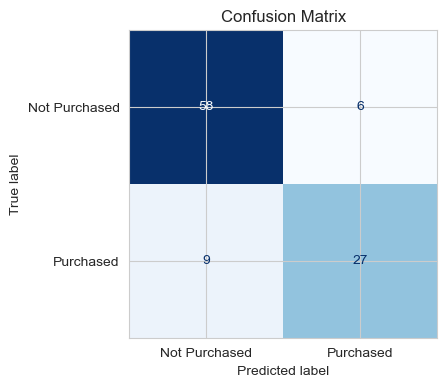

In [8]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(5, 4))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Purchased", "Purchased"])
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Confusion Matrix")
plt.show()

## 7. Visualize the Decision Boundary
Since we only have two features, we can plot the model's decision regions directly: every point in Age x EstimatedSalary space gets colored by what the model would predict there, with the actual test points overlaid.

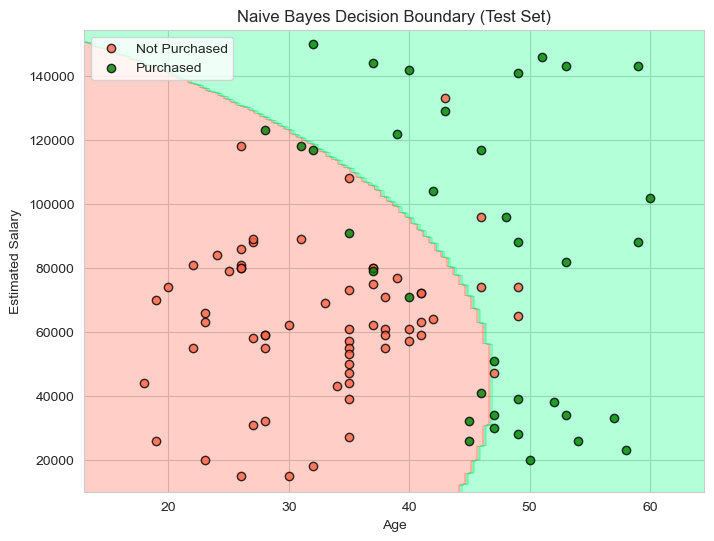

In [9]:
from matplotlib.colors import ListedColormap

X_set, y_set = scaler.inverse_transform(X_test_scaled), y_test

X1, X2 = np.meshgrid(
    np.arange(X_set[:, 0].min() - 5, X_set[:, 0].max() + 5, 0.5),
    np.arange(X_set[:, 1].min() - 5000, X_set[:, 1].max() + 5000, 500)
)
grid = scaler.transform(np.array([X1.ravel(), X2.ravel()]).T)
Z = model.predict(grid).reshape(X1.shape)

plt.figure(figsize=(8, 6))
plt.contourf(X1, X2, Z, alpha=0.3, cmap=ListedColormap(("tomato", "springgreen")))

for cls, color, label in zip([0, 1], ["tomato", "green"], ["Not Purchased", "Purchased"]):
    mask = y_set == cls
    plt.scatter(X_set[mask, 0], X_set[mask, 1], c=color, edgecolor="k", label=label, alpha=0.8)

plt.xlabel("Age")
plt.ylabel("Estimated Salary")
plt.title("Naive Bayes Decision Boundary (Test Set)")
plt.legend()
plt.show()

## Interpretation
- **Accuracy** tells you the overall fraction of correct predictions, but check the classification report too — with imbalanced classes, accuracy alone can be misleading.
- **Confusion matrix**: the diagonal is correct predictions; off-diagonal cells are the two error types (false positives, false negatives).
- **Decision boundary**: Naive Bayes with Gaussian likelihoods produces smooth, roughly elliptical/curved regions (unlike, say, a linear classifier's straight boundary) — you can see how older users with mid-to-high salaries are more likely to be predicted as purchasers.